# 402 - Deep Convolutional Models: Case Studies

## Table of Contents
[1.2. Building Neural Networks with PyTorch](#Building-Neural-Networks-with-PyTorch)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.1. PyTorch Fundamentals](#PyTorch-Fundamentals)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.2. Implementing Linear Regression](#Implementing-Linear-Regression)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.3. Implementing a Regression MLP](#Implementing-a-Regression-MLP)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.4. Implementing Mini-Batch Gradient Descent Using DataLoaders](#Implementing-Mini-Batch-Gradient-Descent-Using-DataLoaders)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.5. Model Evaluation](#Model-Evaluation)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.6. Building Nonsequential Models Using Custom Modules](#Building-Nonsequential-Models-Using-Custom-Modules)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.7. Building an Image Classifier with PyTorch](#Building-an-Image-Classifier-with-PyTorch)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.8. Fine-Tuning Neural Network Hyperparameters with Optuna](#Fine-Tuning-Neural-Network-Hyperparameters-with-Optuna)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.9. Saving and Loading PyTorch Models](#Saving-and-Loading-Pytorch-Models)<br>

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Note:</strong> Before going over this week's programming assignments, I'm going to study Chapters 10 and 11 from Geron's <i>Hands-on Machine Learning with Scikit-Learn and PyTorch.</i> To learn how to implement models using PyTorch's high-level API.
</div>

In [159]:
# Standard Imports
import numpy as np
import matplotlib.pyplot as plt
import torch

## Building Neural Networks with PyTorch

### PyTorch Fundamentals

In [4]:
# Check available devices
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

mps


In [210]:
# Hardware Accelarators: GPU vs CPU (Hydrogen bomb vs. coughing baby)
# CPU
M = torch.rand((1000,1000))
%timeit M @ M.T

# GPU
M = torch.rand((1000,1000), device='mps')
%timeit M @ M.T

980 μs ± 5.04 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
783 μs ± 3.54 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [81]:
# Autograd - Optimizing a quadratic function
learning_rate = 0.01
x = torch.tensor(-15., requires_grad=True, device=device)
y = torch.tensor(-19., requires_grad=True, device=device)
x_data = [x.detach().cpu()]
y_data = [y.detach().cpu()]
for iteration in range(100):
    f = x**2 + 10*y**2     # Forward
    f.backward()        # Backward

    # Update
    with torch.no_grad():
        x -= learning_rate * x.grad
        y -= learning_rate * y.grad

    # Log data
    x_data.append(x.detach().cpu())
    y_data.append(y.detach().cpu())

    # Reset grads
    x.grad.zero_()
    y.grad.zero_()

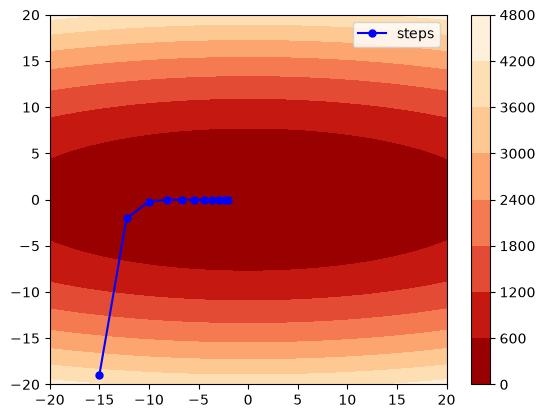

In [101]:
# Plot results
N = 100
xx = np.linspace(-20.0, 20.0, N)
yy = np.linspace(-20.0, 20.0, N)
XX, YY = np.meshgrid(xx, yy)
z = XX**2 + 10*YY**2
fig, ax = plt.subplots()
cs = ax.contourf(XX, YY, z, cmap="OrRd_r")
cbar = fig.colorbar(cs)

ax.plot(x_data[::10], y_data[::10], marker='o', ms = 5, linestyle='-', color='blue', label='steps')
ax.legend()
plt.show()

### Implementing Linear Regression

In [110]:
# Data - California Housing
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from pathlib import Path
X, y = fetch_california_housing(data_home=Path.cwd().joinpath('data'),
                                download_if_missing=True,
                                return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42)

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_val shape:', X_val.shape)
print('y_val shape:', y_val.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (11610, 8)
y_train shape: (11610,)
X_val shape: (3870, 8)
y_val shape: (3870,)
X_test shape: (5160, 8)
y_test shape: (5160,)


In [116]:
# Preprocessing - Tensorize and Scale
X_train = torch.FloatTensor(X_train)
X_val = torch.FloatTensor(X_val)
X_test = torch.FloatTensor(X_test)
means = X_train.mean(dim=0, keepdim=True)
stds = X_train.std(dim=0, keepdim=True)
X_train = (X_train - means) / stds
X_val = (X_val - means) / stds
X_test = (X_test - means) / stds

y_train = torch.FloatTensor(y_train).reshape(-1,1)
y_val = torch.FloatTensor(y_val).reshape(-1,1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

print(f'X_train means (are all close to zero?):', torch.allclose(X_train.mean(), torch.tensor(0.0)))
print('X_train std (are all close to one?):', torch.allclose(X_train.std(dim=0), torch.tensor(1.0)))
print('y_train shape:', y_train.shape)
print('y_val shape:', y_val.shape)
print('y_test shape:', y_test.shape)

X_train means (are all close to zero?): True
X_train std (are all close to one?): True
y_train shape: torch.Size([11610, 1])
y_val shape: torch.Size([3870, 1])
y_test shape: torch.Size([5160, 1])


#### Using Tensors and Autograd

In [144]:
# Initialize Parameters
torch.manual_seed(42)
n_in = X_train.shape[1]
W = torch.randn((n_in, 1), requires_grad=True, device=device)
b = torch.tensor(0., requires_grad=True, device=device)

print('W.shape:', W.shape)
print('b.shape:', b.shape)
print('W\n', W)
print('b\n', b)

W.shape: torch.Size([8, 1])
b.shape: torch.Size([])
W
 tensor([[ 1.7563],
        [-0.2539],
        [-0.9927],
        [-0.6515],
        [-0.4827],
        [-0.1972],
        [ 0.4944],
        [ 0.2693]], device='mps:0', requires_grad=True)
b
 tensor(0., device='mps:0', requires_grad=True)


In [145]:
# Training
learning_rate = 0.4
epochs = 20

for iteration in range(epochs):
    # Forward
    y_train_pred = torch.matmul(X_train.to(device), W) + b
    mse_cost = ((y_train_pred - y_train.to(device))**2).mean(dim=0, keepdim=True)

    # Backward
    mse_cost.backward()

    with torch.no_grad():
        # Weight update
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad

        # Reset grads
        W.grad.zero_()
        b.grad.zero_()

    print(f"Epoch {iteration + 1}/{epochs}, MSE: {mse_cost.item()}")

Epoch 1/20, MSE: 7.979630470275879
Epoch 2/20, MSE: 1.3271340131759644
Epoch 3/20, MSE: 0.8188687562942505
Epoch 4/20, MSE: 0.7123928666114807
Epoch 5/20, MSE: 0.6727661490440369
Epoch 6/20, MSE: 0.6517986059188843
Epoch 7/20, MSE: 0.6373873949050903
Epoch 8/20, MSE: 0.6258752346038818
Epoch 9/20, MSE: 0.6160195469856262
Epoch 10/20, MSE: 0.6073315143585205
Epoch 11/20, MSE: 0.5995773077011108
Epoch 12/20, MSE: 0.5926181077957153
Epoch 13/20, MSE: 0.5863552093505859
Epoch 14/20, MSE: 0.5807100534439087
Epoch 15/20, MSE: 0.5756163001060486
Epoch 16/20, MSE: 0.5710160136222839
Epoch 17/20, MSE: 0.566858172416687
Epoch 18/20, MSE: 0.5630974769592285
Epoch 19/20, MSE: 0.5596936345100403
Epoch 20/20, MSE: 0.5566105842590332


In [146]:
# Validation and Test
with torch.no_grad():
    y_val_pred = torch.matmul(X_val, W.cpu()) + b.cpu()
    mse_val = ((y_val_pred - y_val)**2).mean(dim=0, keepdim=True)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = torch.matmul(X_test, W.cpu()) + b.cpu()
    mse_test = ((y_test_pred - y_test)**2).mean(dim=0, keepdim=True)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.179
Test MSE: 0.563


#### Using PyTorch's High-Level API

In [154]:
# Instantiation of Module
import torch.nn as nn
torch.manual_seed(42)
model = nn.Linear(in_features=n_in, out_features=1, bias=True)

print(model.bias)
print(model.weight)

# Sample prediction
print('prediction:\n', model(X_train[:2]))
print('actual:\n', y_train[:2])

Parameter containing:
tensor([0.3117], requires_grad=True)
Parameter containing:
tensor([[ 0.2703,  0.2935, -0.0828,  0.3248, -0.0775,  0.0713, -0.1721,  0.2076]],
       requires_grad=True)
prediction:
 tensor([[-0.4718],
        [ 0.1131]], grad_fn=<AddmmBackward0>)
actual:
 tensor([[1.4420],
        [1.6870]])


In [155]:
# Training
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}')

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 4.3378520011901855
Epoch 2/20, Loss: 0.7802940607070923
Epoch 3/20, Loss: 0.6253843307495117
Epoch 4/20, Loss: 0.6060435175895691
Epoch 5/20, Loss: 0.5956299304962158
Epoch 6/20, Loss: 0.587356686592102
Epoch 7/20, Loss: 0.5802989602088928
Epoch 8/20, Loss: 0.5741382241249084
Epoch 9/20, Loss: 0.5687100291252136
Epoch 10/20, Loss: 0.5639079213142395
Epoch 11/20, Loss: 0.5596510767936707
Epoch 12/20, Loss: 0.5558737516403198
Epoch 13/20, Loss: 0.5525193810462952
Epoch 14/20, Loss: 0.5495391488075256
Epoch 15/20, Loss: 0.5468899011611938
Epoch 16/20, Loss: 0.544533908367157
Epoch 17/20, Loss: 0.5424376726150513
Epoch 18/20, Loss: 0.5405715703964233
Epoch 19/20, Loss: 0.5389097332954407
Epoch 20/20, Loss: 0.5374288558959961


In [157]:
# Validation and Test
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.169
Test MSE: 0.538


### Implementing a Regression MLP

In [161]:
# Instantiate model, optimizer, and loss function
torch.manual_seed(42)
learning_rate = 0.1
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

In [162]:
# Training
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 5.045480251312256
Epoch 2/20, Loss: 2.0523130893707275
Epoch 3/20, Loss: 1.0039886236190796
Epoch 4/20, Loss: 0.857014000415802
Epoch 5/20, Loss: 0.7740675210952759
Epoch 6/20, Loss: 0.7225848436355591
Epoch 7/20, Loss: 0.6893725991249084
Epoch 8/20, Loss: 0.6669032573699951
Epoch 9/20, Loss: 0.650773823261261
Epoch 10/20, Loss: 0.6383934020996094
Epoch 11/20, Loss: 0.6281994581222534
Epoch 12/20, Loss: 0.6193400025367737
Epoch 13/20, Loss: 0.6113174557685852
Epoch 14/20, Loss: 0.6038705706596375
Epoch 15/20, Loss: 0.5968309044837952
Epoch 16/20, Loss: 0.5901119709014893
Epoch 17/20, Loss: 0.5836468935012817
Epoch 18/20, Loss: 0.5774064064025879
Epoch 19/20, Loss: 0.5713556408882141
Epoch 20/20, Loss: 0.5654448866844177


In [163]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.528
Test MSE: 0.550


### Implementing Mini-Batch Gradient Descent Using DataLoaders
For PyTorch's `torch.utils.data.DataLoader` to work, the dataset must have at least two methods: `__len__(self)` and `__getitem__(self, index)`. Tensors have these.

In [169]:
# Check dataset attributes
print('X_train has __len__ method:', hasattr(X_train, '__len__'))
print('X_train has __getitem__ method:', hasattr(X_train, '__getitem__'))

X_train has __len__ method: True
X_train has __getitem__ method: True


In [170]:
# Wrapping in dataset object and creating data loader
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [177]:
# Training with Minibatch GD
torch.manual_seed(42)
learning_rate = 0.02
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

def train_mbgd(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()   # Training mode??? idk...
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

train_mbgd(model, train_loader, optimizer, mse, 20, device)

Epoch 1/20, Loss: 0.5900079238102784
Epoch 2/20, Loss: 0.40617793351074827
Epoch 3/20, Loss: 0.3812409350448311
Epoch 4/20, Loss: 0.3639697381641072
Epoch 5/20, Loss: 0.35405540368439453
Epoch 6/20, Loss: 0.35315823936488355
Epoch 7/20, Loss: 0.3418332261469417
Epoch 8/20, Loss: 0.3421076757021259
Epoch 9/20, Loss: 0.34126834015059937
Epoch 10/20, Loss: 0.3446410464446847
Epoch 11/20, Loss: 0.3318698472562356
Epoch 12/20, Loss: 0.3272509280538928
Epoch 13/20, Loss: 0.3250868026762233
Epoch 14/20, Loss: 0.3227055189788914
Epoch 15/20, Loss: 0.31980858085508534
Epoch 16/20, Loss: 0.31709102038586096
Epoch 17/20, Loss: 0.31348098657112705
Epoch 18/20, Loss: 0.3110350068235524
Epoch 19/20, Loss: 0.3088778259000568
Epoch 20/20, Loss: 0.31138984235074163


In [176]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model.to('cpu')(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model.to('cpu')(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.307
Test MSE: 0.314


### Model Evaluation

In [194]:
# Define Evaluator
from collections.abc import Callable

def evaluate(model, loader, metric_fn, agg_fn: Callable = torch.mean, device='mps'):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric = metric_fn(y_pred, y_mb)
            metrics.append(metric)
    return agg_fn(torch.stack(metrics))

In [196]:
# Build Validation Dataset
val_dataset = TensorDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=32)

In [197]:
# Validation with MSE
val_mse = evaluate(model, val_loader, mse)
print(f'Validation MSE: {val_mse.item():.3f}')

Validation MSE: 0.307


In [198]:
# Validation with RMSE
val_rmse = evaluate(model, val_loader, mse, lambda metrics: torch.sqrt(torch.mean(metrics)))
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation RMSE: 0.554


In [208]:
# Implementation with TorchMetrics
from torchmetrics import MeanSquaredError, Metric

def evaluate_tm(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

# with MSE
mse_tm = MeanSquaredError().to(device)
val_mse = evaluate_tm(model, val_loader, mse_tm)

# with RMSE
rmse_tm = MeanSquaredError(squared=False).to(device)
val_rmse = evaluate_tm(model, val_loader, rmse_tm)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation MSE: 0.307
Validation RMSE: 0.554


### Building Nonsequential Models Using Custom Modules

#### Example: Wide and deep neural network
<img src="references/Screenshot%202026-11-03%20at%203.03.30%E2%80%AFAM.png" width=600></img><br>
*Image taken from Geron's book*

It is useful to have a wide part to learn simple rules about the data, and a deep part that learns the complex patterns.

By concatenating the input with the output of the deep part, it would be like the network is fitting both a simple linear model and a more complex MLP model.

In [211]:
# Create wide and deep neural network as custom module
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features, 1)
    def forward(self, X):
        deep_out = self.deep_stack(X)
        wide_and_deep = torch.concat([deep_out, X], dim=1)
        return self.output_layer(wide_and_deep)

In [212]:
# Try-out the network
model = WideAndDeep(n_in).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 1.407197772799773
Epoch 2/20, Loss: 0.6222839168262516
Epoch 3/20, Loss: 0.5577010124323979
Epoch 4/20, Loss: 0.523649293586406
Epoch 5/20, Loss: 0.5012539706540086
Epoch 6/20, Loss: 0.4812205669696863
Epoch 7/20, Loss: 0.4676030965827866
Epoch 8/20, Loss: 0.45614281726173106
Epoch 9/20, Loss: 0.4447738014834066
Epoch 10/20, Loss: 0.43726694093568724
Epoch 11/20, Loss: 0.43037312170653585
Epoch 12/20, Loss: 0.4238673175495296
Epoch 13/20, Loss: 0.41936564413343075
Epoch 14/20, Loss: 0.4139681010198012
Epoch 15/20, Loss: 0.41080679430415135
Epoch 16/20, Loss: 0.40548001703025693
Epoch 17/20, Loss: 0.4011411857062135
Epoch 18/20, Loss: 0.3959003698922861
Epoch 19/20, Loss: 0.39401847489776076
Epoch 20/20, Loss: 0.3886882056564914


In [215]:
# Validate and Test
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32)

val_mse = evaluate_tm(model, val_loader, mse_tm, device)
test_mse = evaluate_tm(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.686
Test MSE: 0.387


#### Building Models with Multiple Inputs

Sometimes we want different subsets of the features as inputs to the deep and wide parts. And they do not necessarily have the same dimensions, e.g., text as input to the wide part and image to the deep part.<br>
<img src="references/Screenshot 2026-11-03 at 3.34.41 AM.png" width=600></img><br>
*Image taken from Geron's book*

In [242]:
# create a dataset subclass for deep and wide
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        input_dict = {"X_wide": self.X_wide[index], "X_deep": self.X_deep[index]}
        return input_dict, self.y[index]

# Modifying Wide and Deep class
class WideAndDeepV2(nn.Module):
    def __init__(self, n_features_wide, n_features_deep):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features_deep, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features_wide, 1)
    def forward(self, X_wide, X_deep):
        deep_out = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_out], dim=1)
        return self.output_layer(wide_and_deep)

# modify training function
def train_mbgd_v2(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = {name: X.to(device) for name, X in X_mb.items()}
            y_mb = y_mb.to(device)
            y_out = model(**X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

# modify evaluation function
def evaluate_tm_v2(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = {name: X.to(device) for name, X in X_mb.items()}, y_mb.to(device)
            y_pred = model(**X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

In [240]:
# Prepare dataset and loader
features_wide = [0,1,2,3,4]
features_deep = [2, 3, 4, 5, 6, 7]

# Training data
X_wide_train = X_train[:,features_wide]
X_deep_train = X_train[:,features_deep]
train_dataset = WideAndDeepDataset(X_wide_train, X_deep_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Validation data
X_wide_val = X_train[:,features_wide]
X_deep_val = X_train[:,features_deep]
val_dataset = WideAndDeepDataset(X_wide_val, X_deep_val, y_train)
val_loader = DataLoader(val_dataset, batch_size=32)

# Test data
X_wide_test = X_test[:,features_wide]
X_deep_test = X_test[:,features_deep]
test_dataset = WideAndDeepDataset(X_wide_test, X_deep_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32)

In [243]:
# WideAndDeepV2 training
model = WideAndDeepV2(len(features_wide), len(features_deep)).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd_v2(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 1.3770210886625547
Epoch 2/20, Loss: 0.578902352281682
Epoch 3/20, Loss: 0.5331012676499661
Epoch 4/20, Loss: 0.5059909784625117
Epoch 5/20, Loss: 0.48632471722179155
Epoch 6/20, Loss: 0.4705306493672735
Epoch 7/20, Loss: 0.4614838652520559
Epoch 8/20, Loss: 0.4525047624386783
Epoch 9/20, Loss: 0.44673237600938387
Epoch 10/20, Loss: 0.44144383948310717
Epoch 11/20, Loss: 0.43748011288512795
Epoch 12/20, Loss: 0.4345314515605081
Epoch 13/20, Loss: 0.43090607759900396
Epoch 14/20, Loss: 0.42792647961489605
Epoch 15/20, Loss: 0.4241003469011374
Epoch 16/20, Loss: 0.4225067424257982
Epoch 17/20, Loss: 0.41894331519090344
Epoch 18/20, Loss: 0.41813471492422416
Epoch 19/20, Loss: 0.41525498850358455
Epoch 20/20, Loss: 0.4134020935507521


In [244]:
# WideAndDeepV2 Evaluation and Testing
val_mse = evaluate_tm_v2(model, val_loader, mse_tm, device)
test_mse = evaluate_tm_v2(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.411
Test MSE: 0.408


#### Building Models with Multiple Outputs
<img src="references/Screenshot 2026-11-04 at 3.00.23 AM.png" width=600>

Examples of use cases of multiple output networks (multitasking):
- (1) locating the main object in the picture (regression), and (2) classifying the main object (classification).
- multitask classification, e.g., identifying the person's facial expression and identifying whether they are wearing glasses or not. It is possible to train two different networks for these tasks, but a single network could be better since it can utilize information across all tasks.
- regularization, e.g., adding an auxilliary output to ensure that a subset of the layers learns something useful on its own.

In [257]:
# Example: Adding an Auxilliary Output to WideAndDeep
class WideAndDeepV3(nn.Module):
    def __init__(self, n_features_wide, n_features_deep):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features_deep, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features_wide, 1)
        self.aux_output_layer = nn.Linear(40, 1)
    def forward(self, X_wide, X_deep):
        deep_out = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_out], dim=1)
        main_output = self.output_layer(wide_and_deep)
        aux_output = self.aux_output_layer(deep_out)
        return main_output, aux_output

# modify training function
def train_mbgd_v3(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = {name: X.to(device) for name, X in X_mb.items()}
            y_mb = y_mb.to(device)
            y_main_out, y_aux_out = model(**X_mb)
            loss = 0.8*criterion(y_main_out, y_mb) + 0.2*criterion(y_aux_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

# modify evaluation function
def evaluate_tm_v3(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = {name: X.to(device) for name, X in X_mb.items()}, y_mb.to(device)
            y_pred, _ = model(**X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

In [258]:
# WideAndDeepV3 Training
model = WideAndDeepV3(len(features_wide), len(features_deep)).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd_v3(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 2.0689879230559693
Epoch 2/20, Loss: 0.9086026264922515
Epoch 3/20, Loss: 0.8063730572903498
Epoch 4/20, Loss: 0.7626559095538255
Epoch 5/20, Loss: 0.7272534316118526
Epoch 6/20, Loss: 0.6946154320796485
Epoch 7/20, Loss: 0.6650562163458273
Epoch 8/20, Loss: 0.6361457386610884
Epoch 9/20, Loss: 0.6090540474957008
Epoch 10/20, Loss: 0.584729291898572
Epoch 11/20, Loss: 0.5623866686038914
Epoch 12/20, Loss: 0.5451155532103741
Epoch 13/20, Loss: 0.5295689058584894
Epoch 14/20, Loss: 0.5170929819296989
Epoch 15/20, Loss: 0.5057472567994927
Epoch 16/20, Loss: 0.4976284134024649
Epoch 17/20, Loss: 0.48938641229270097
Epoch 18/20, Loss: 0.48236046329945237
Epoch 19/20, Loss: 0.4768454247241235
Epoch 20/20, Loss: 0.47130137537287753


In [259]:
# WideAndDeepV2 Evaluation and Testing
val_mse = evaluate_tm_v3(model, val_loader, mse_tm, device)
test_mse = evaluate_tm_v3(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.421
Test MSE: 0.414


### Building an Image Classifier with PyTorch

In [307]:
# Using TorchVision to Load the Dataset
from torchvision import datasets
from torch.utils.data import random_split
import torchvision.transforms.v2 as T

# The downloaded image will be a tuple containing the input image and the label
# The dtype of the image is PIL Image, we can transform it to a torch.Image object (subclass of Tensor) via ToImage transform
# We will then use ToDtype transform for both converting the elements to float32 and scaling.
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_val_data = datasets.FashionMNIST(root = Path.cwd().joinpath('data'), train = True, download = True, transform = toTensor)
test_data = datasets.FashionMNIST(root=Path.cwd().joinpath('data'), train = False, download = True, transform = toTensor)

torch.manual_seed(42)
train_data, val_data = random_split(train_and_val_data, [55000, 5000])

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

print('FashionMNIST Dataset')
print('--------------------')
print(f'  Training size: {len(train_data)}')
print(f'  Validation size: {len(val_data)}')
print(f'  Test size: {len(test_data)}')
print(f'  Example shape: {tuple(train_data[0][0].shape)}')
print(f'  Classes: {list(train_and_val_data.classes)}')

FashionMNIST Dataset
--------------------
  Training size: 55000
  Validation size: 5000
  Test size: 10000
  Example shape: (1, 28, 28)
  Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


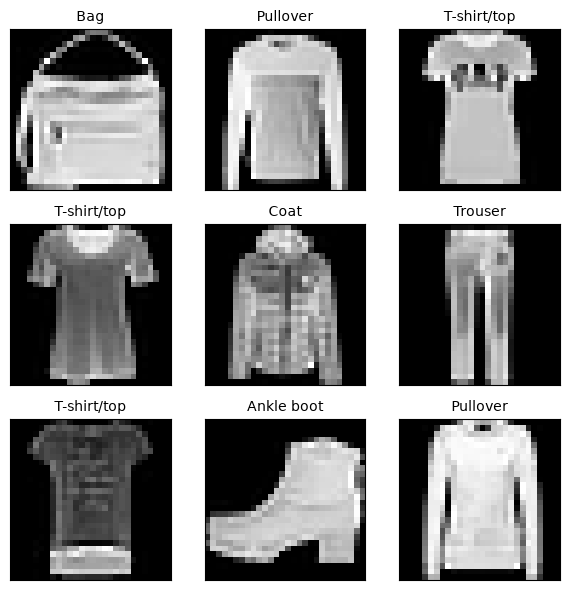

In [312]:
# Image samples
fig, axs = plt.subplots(3, 3, figsize=(6,6),
                        subplot_kw={'xticks': [], 'yticks': []},)

torch.manual_seed(42)
sample_idxs = torch.randint(0, len(train_data), (9,))
classes = train_and_val_data.classes

for i,ax in zip(sample_idxs, axs.flat):
    img, int_label = train_data[i]
    ax.imshow(img[0,:,:], cmap='gray', interpolation='nearest')
    ax.set_title(classes[int_label], fontsize=10)

fig.tight_layout()
plt.show()

In [318]:
# Define the Image Classifier
class ImageClassifier(nn.Module):
    def __init__(self, n_features, n_hidden1, n_hidden2, n_clases):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_features, n_hidden1), nn.ReLU(),
            nn.Linear(n_hidden1, n_hidden2), nn.ReLU(),
            nn.Linear(n_hidden2, n_clases),
        )

    def forward(self, X):
        return self.model(X)

def train_eval_mbgd(model, train_dataloader, val_dataloader, optimizer, criterion, n_epochs, device='mps'):
    training_loss = 0
    val_losses = []
    for epoch in range(n_epochs):
        model.train()
        for X_mb, y_mb in train_dataloader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        val_losses.append(evaluate(model, val_dataloader, criterion, device=device))
        training_loss /= len(train_dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

    return val_losses

torch.manual_seed(42)
learning_rate = 0.001
model = ImageClassifier(28*28, 300, 100, 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
val_losses = {learning_rate: train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)}

Epoch 1/20, Loss: 2.2253630061424214
Epoch 2/20, Loss: 1.8707563159295353
Epoch 3/20, Loss: 1.3588646797261352
Epoch 4/20, Loss: 1.0794391798947611
Epoch 5/20, Loss: 0.9295722185587577
Epoch 6/20, Loss: 0.8404554915885291
Epoch 7/20, Loss: 0.7821694133072542
Epoch 8/20, Loss: 0.7400795841368097
Epoch 9/20, Loss: 0.7065606357553469
Epoch 10/20, Loss: 0.6779744484628184
Epoch 11/20, Loss: 0.6536839761889467
Epoch 12/20, Loss: 0.6317051931258431
Epoch 13/20, Loss: 0.612911302831625
Epoch 14/20, Loss: 0.5957800109458722
Epoch 15/20, Loss: 0.5804798422642723
Epoch 16/20, Loss: 0.5671424194588681
Epoch 17/20, Loss: 0.5546887933886843
Epoch 18/20, Loss: 0.5439572424901253
Epoch 19/20, Loss: 0.5341335748780814
Epoch 20/20, Loss: 0.5251067516937091


In [326]:
# Find best LR
lrs = [7.5e-3, 2.0e-2, 4.0e-2]
for lr in lrs:
    model = ImageClassifier(28*28, 300, 100, 10).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    print(f"\n--- Starting Training with Learning Rate: {lr} ---")
    val_losses[lr] = train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)


--- Starting Training with Learning Rate: 0.0075 ---
Epoch 1/20, Loss: 1.2554879166866333
Epoch 2/20, Loss: 0.6667154405151585
Epoch 3/20, Loss: 0.5563689125442747
Epoch 4/20, Loss: 0.5022332718554536
Epoch 5/20, Loss: 0.47182592060308337
Epoch 6/20, Loss: 0.45159901729738794
Epoch 7/20, Loss: 0.4353801063056318
Epoch 8/20, Loss: 0.4221810500983651
Epoch 9/20, Loss: 0.4111706090389922
Epoch 10/20, Loss: 0.40025536901908876
Epoch 11/20, Loss: 0.3921275016943264
Epoch 12/20, Loss: 0.3825498406225982
Epoch 13/20, Loss: 0.3751426165929116
Epoch 14/20, Loss: 0.36795733323252516
Epoch 15/20, Loss: 0.3608847152737224
Epoch 16/20, Loss: 0.3543960175881851
Epoch 17/20, Loss: 0.34829909997344977
Epoch 18/20, Loss: 0.34260534801487524
Epoch 19/20, Loss: 0.33648383926611575
Epoch 20/20, Loss: 0.3311773663022192

--- Starting Training with Learning Rate: 0.02 ---
Epoch 1/20, Loss: 0.873695414571862
Epoch 2/20, Loss: 0.5068350881100077
Epoch 3/20, Loss: 0.45139520323642673
Epoch 4/20, Loss: 0.41847

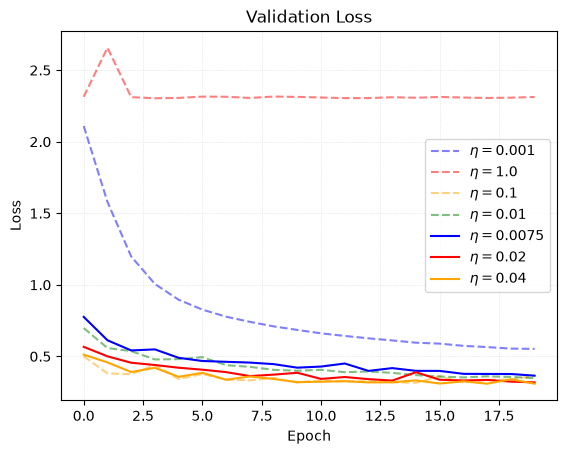

In [330]:
# Plot validation losses by LR
colors = ['blue', 'red', 'orange', 'green', 'blue', 'red', 'orange']
for color, record in zip(colors, val_losses.items()):
    lr, loss_ = record
    ls, alpha = ('-', 1.0) if lr in [7.5e-3, 2.0e-2, 4.0e-2] else ('--', 0.5)
    plt.plot(range(len(loss_)), list(map(lambda x: x.to('cpu'), loss_)), ls=ls, alpha=alpha, color=color, label=rf'$\eta=${lr}')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(visible=True, ls=':', alpha=0.5)
plt.title('Validation Loss')
plt.legend()
plt.show()

In [332]:
# Train on best LR
torch.manual_seed(42)
learning_rate = 0.02
model = ImageClassifier(28*28, 300, 100, 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
val_loss = train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 0.8871514641350962
Epoch 2/20, Loss: 0.5105545521298597
Epoch 3/20, Loss: 0.4513503931736123
Epoch 4/20, Loss: 0.41689052191922654
Epoch 5/20, Loss: 0.3922161876907243
Epoch 6/20, Loss: 0.37297244020468084
Epoch 7/20, Loss: 0.3566452082618459
Epoch 8/20, Loss: 0.34308690884851084
Epoch 9/20, Loss: 0.3309794706941491
Epoch 10/20, Loss: 0.31948581056233205
Epoch 11/20, Loss: 0.31165537553057343
Epoch 12/20, Loss: 0.3003781594011948
Epoch 13/20, Loss: 0.2943625809382968
Epoch 14/20, Loss: 0.2862406330876488
Epoch 15/20, Loss: 0.2790624464969183
Epoch 16/20, Loss: 0.27314521411560133
Epoch 17/20, Loss: 0.2662685405304896
Epoch 18/20, Loss: 0.2598227631766528
Epoch 19/20, Loss: 0.2550154162689214
Epoch 20/20, Loss: 0.24942759899276934


In [335]:
# Validation Accuracy
from torchmetrics import Accuracy

accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
val_score = evaluate_tm(model, val_loader, accuracy)
test_score = evaluate_tm(model, test_loader, accuracy)

print(f'Validation score: {val_score:.2%}')
print(f'Test score: {test_score:.2%}')

Validation score: 87.36%
Test score: 87.45%


*Note:* The book reached a validation accuracy of 87.2%.

In [349]:
# Inference - Using sample data
idxs = torch.randint(0,32,(5,))
X_new, y_new = next(iter(val_loader))
X_new, y_new = X_new[idxs], y_new[idxs]
with torch.no_grad():
    y_pred = model(X_new.to(device)).argmax(dim=1)

for y_pred_, y_new in zip(y_pred, y_new):
    results = f'predicted={classes[y_pred_]}, actual={classes[y_new]}'
    if y_pred_ == y_new:
        print(f'\033[92m{results}\033[0m')
    else:
        print(f'\033[91m{results}\033[0m')

predicted=Sneaker, actual=Ankle boot
predicted=T-shirt/top, actual=Shirt
predicted=Pullover, actual=Pullover
predicted=Coat, actual=Coat
predicted=Coat, actual=Coat


### Fine-Tuning Neural Network Hyperparameters with Optuna

In [370]:
# Create the objective function based on a "trial" object
import optuna

def objective(trial):
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-1, log=True)
    n_hidden1 = trial.suggest_int("n_hidden1", 20, 300)
    n_hidden2 = trial.suggest_int("n_hidden2", 20, 100)

    model = ImageClassifier(28*28, n_hidden1, n_hidden2, 10).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    train_mbgd(model, train_loader, optimizer, loss, 20, device)

    accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
    val_score = evaluate_tm(model, val_loader, accuracy)

    return val_score

In [371]:
# Optimize
torch.manual_seed(42)
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=5)

[I 2026-11-04 23:11:05,120] A new study created in memory with name: no-name-0b730f9c-4e45-4538-b559-c6f287185a86


Epoch 1/20, Loss: 2.2797442356329314
Epoch 2/20, Loss: 2.2195355163148274
Epoch 3/20, Loss: 2.1322961467576236
Epoch 4/20, Loss: 1.995263529039876
Epoch 5/20, Loss: 1.8075773124851422
Epoch 6/20, Loss: 1.6122357305434731
Epoch 7/20, Loss: 1.4479048115869484
Epoch 8/20, Loss: 1.3194354739894916
Epoch 9/20, Loss: 1.2188437763775408
Epoch 10/20, Loss: 1.138270098442756
Epoch 11/20, Loss: 1.0724085515050266
Epoch 12/20, Loss: 1.018074332797744
Epoch 13/20, Loss: 0.972747384703853
Epoch 14/20, Loss: 0.9346325389511787
Epoch 15/20, Loss: 0.9022596356405017
Epoch 16/20, Loss: 0.8743048158336623
Epoch 17/20, Loss: 0.8500910638772963
Epoch 18/20, Loss: 0.8288344784868373
Epoch 19/20, Loss: 0.8098432614150688


[I 2026-11-04 23:12:23,101] Trial 0 finished with value: 0.6985999941825867 and parameters: {'learning_rate': 0.00031489116479568613, 'n_hidden1': 287, 'n_hidden2': 79}. Best is trial 0 with value: 0.6985999941825867.


Epoch 20/20, Loss: 0.7928311671304629
Epoch 1/20, Loss: 1.9494676347247661
Epoch 2/20, Loss: 1.0859253624483063
Epoch 3/20, Loss: 0.8212321055762665
Epoch 4/20, Loss: 0.7216854172061316
Epoch 5/20, Loss: 0.6608664076895724
Epoch 6/20, Loss: 0.6148379687956751
Epoch 7/20, Loss: 0.5787500794890693
Epoch 8/20, Loss: 0.5516188831348626
Epoch 9/20, Loss: 0.5297672925109165
Epoch 10/20, Loss: 0.5127810466575994
Epoch 11/20, Loss: 0.49781989659038656
Epoch 12/20, Loss: 0.48697963065481775
Epoch 13/20, Loss: 0.4765264744083536
Epoch 14/20, Loss: 0.4678072581286645
Epoch 15/20, Loss: 0.45950764010370687
Epoch 16/20, Loss: 0.4526501414691823
Epoch 17/20, Loss: 0.44598748008118383
Epoch 18/20, Loss: 0.440417700370937
Epoch 19/20, Loss: 0.434692997371039
Epoch 20/20, Loss: 0.43009306502767264


[I 2026-11-04 23:13:35,064] Trial 1 finished with value: 0.8417999744415283 and parameters: {'learning_rate': 0.0024810409748678114, 'n_hidden1': 63, 'n_hidden2': 32}. Best is trial 1 with value: 0.8417999744415283.


Epoch 1/20, Loss: 2.2975091845438604
Epoch 2/20, Loss: 2.2955670072371865
Epoch 3/20, Loss: 2.292265012262965
Epoch 4/20, Loss: 2.2889390498430933
Epoch 5/20, Loss: 2.285617873613541
Epoch 6/20, Loss: 2.2822983108459716
Epoch 7/20, Loss: 2.278999768964266
Epoch 8/20, Loss: 2.2757256319311994
Epoch 9/20, Loss: 2.2724640248917383
Epoch 10/20, Loss: 2.269211228043546
Epoch 11/20, Loss: 2.265958783615548
Epoch 12/20, Loss: 2.2626905426013675
Epoch 13/20, Loss: 2.2594100555191345
Epoch 14/20, Loss: 2.256104431661844
Epoch 15/20, Loss: 2.2527743944589362
Epoch 16/20, Loss: 2.2494103164647576
Epoch 17/20, Loss: 2.246017104416824
Epoch 18/20, Loss: 2.242581624014579
Epoch 19/20, Loss: 2.2391168707919067
Epoch 20/20, Loss: 2.2356065520507404


[I 2026-11-04 23:14:52,466] Trial 2 finished with value: 0.39660000801086426 and parameters: {'learning_rate': 1.7073967431528103e-05, 'n_hidden1': 263, 'n_hidden2': 68}. Best is trial 1 with value: 0.8417999744415283.


Epoch 1/20, Loss: 1.286665811588627
Epoch 2/20, Loss: 0.664527278130967
Epoch 3/20, Loss: 0.5560476826637791
Epoch 4/20, Loss: 0.5063149858945587
Epoch 5/20, Loss: 0.47892136157988907
Epoch 6/20, Loss: 0.459245729868749
Epoch 7/20, Loss: 0.44374841411100857
Epoch 8/20, Loss: 0.4322537824925258
Epoch 9/20, Loss: 0.4236002193357757
Epoch 10/20, Loss: 0.4152061123057201
Epoch 11/20, Loss: 0.40828672310637737
Epoch 12/20, Loss: 0.40158263110793724
Epoch 13/20, Loss: 0.39638035155122625
Epoch 14/20, Loss: 0.39141391721005947
Epoch 15/20, Loss: 0.3869196092560389
Epoch 16/20, Loss: 0.38147123959759777
Epoch 17/20, Loss: 0.3774561764174009
Epoch 18/20, Loss: 0.37322999744349705
Epoch 19/20, Loss: 0.36910983295002014
Epoch 20/20, Loss: 0.36517594619970417


[I 2026-11-04 23:15:54,271] Trial 3 finished with value: 0.853600025177002 and parameters: {'learning_rate': 0.006796578090758156, 'n_hidden1': 25, 'n_hidden2': 98}. Best is trial 3 with value: 0.853600025177002.


Epoch 1/20, Loss: 0.9132506524739812
Epoch 2/20, Loss: 0.5288567590345504
Epoch 3/20, Loss: 0.4668833621658297
Epoch 4/20, Loss: 0.43044408622347186
Epoch 5/20, Loss: 0.4025570925569345
Epoch 6/20, Loss: 0.38269432045676804
Epoch 7/20, Loss: 0.36433123722286803
Epoch 8/20, Loss: 0.3521570638294562
Epoch 9/20, Loss: 0.33765805008162425
Epoch 10/20, Loss: 0.3289330691056816
Epoch 11/20, Loss: 0.3199815575243613
Epoch 12/20, Loss: 0.31098800491545014
Epoch 13/20, Loss: 0.30246550357247715
Epoch 14/20, Loss: 0.2969857948326206
Epoch 15/20, Loss: 0.29004450991303643
Epoch 16/20, Loss: 0.28379870098038446
Epoch 17/20, Loss: 0.27821431127099977
Epoch 18/20, Loss: 0.2722024019556445
Epoch 19/20, Loss: 0.2678270186866862
Epoch 20/20, Loss: 0.26329725980626534


[I 2026-11-04 23:16:55,531] Trial 4 finished with value: 0.8827999830245972 and parameters: {'learning_rate': 0.02136832907235875, 'n_hidden1': 79, 'n_hidden2': 34}. Best is trial 4 with value: 0.8827999830245972.


In [382]:
# Study results
print('----- Study Result ------')
print(f'Best validation score: {study.best_value:.2%}')
print(f'Best hyperparameters:')
for name, val in study.best_params.items():
    val = f'{val:.3f}' if isinstance(val, float) else val
    print(f' {name}: {val}')

----- Study Result ------
Best validation score: 88.28%
Best hyperparameters:
 learning_rate: 0.021
 n_hidden1: 79
 n_hidden2: 34


In [377]:
# Objective with Pruning
def objective_v1(trial, train_loader, val_loader):
    # Fixed
    n_epochs = 20

    # Variables
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-1, log=True)
    n_hidden1 = trial.suggest_int("n_hidden1", 20, 300)
    n_hidden2 = trial.suggest_int("n_hidden2", 20, 100)

    # Functions
    model = ImageClassifier(28*28, n_hidden1, n_hidden2, 10).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    # Training
    val_score = 0.0
    for epoch in range(n_epochs):
        model.train()
        for X_mb, y_mb in train_loader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        # Validation
        accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
        val_score = evaluate_tm(model, val_loader, accuracy)
        trial.report(val_score, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return val_score

In [378]:
# Optimize with Pruning
pruner = optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=5, interval_steps=1)
study_w_pruning = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
objective_v1_w_data = lambda trial: objective_v1(trial, train_loader=train_loader, val_loader=val_loader)
study_w_pruning.optimize(objective_v1_w_data, n_trials=5)

[I 2026-11-04 23:18:37,133] A new study created in memory with name: no-name-250bb610-1a71-419f-a8ca-805ddad398a6
[I 2026-11-04 23:19:38,504] Trial 0 finished with value: 0.2840000092983246 and parameters: {'learning_rate': 3.613894271216525e-05, 'n_hidden1': 102, 'n_hidden2': 49}. Best is trial 0 with value: 0.2840000092983246.
[I 2026-11-04 23:20:40,438] Trial 1 finished with value: 0.7793999910354614 and parameters: {'learning_rate': 0.0006672367170464204, 'n_hidden1': 240, 'n_hidden2': 36}. Best is trial 1 with value: 0.7793999910354614.
[I 2026-11-04 23:21:41,686] Trial 2 finished with value: 0.8122000098228455 and parameters: {'learning_rate': 0.0011400863701127321, 'n_hidden1': 186, 'n_hidden2': 23}. Best is trial 2 with value: 0.8122000098228455.
[I 2026-11-04 23:22:42,632] Trial 3 finished with value: 0.8375999927520752 and parameters: {'learning_rate': 0.0026926469100861782, 'n_hidden1': 67, 'n_hidden2': 25}. Best is trial 3 with value: 0.8375999927520752.
[I 2026-11-04 23:23

In [383]:
# Results with Pruning
print('----- Study Result ------')
print(f'Best validation score: {study_w_pruning.best_value:.2%}')
print(f'Best hyperparameters:')
for name, val in study_w_pruning.best_params.items():
    val = f'{val:.3f}' if isinstance(val, float) else val
    print(f' {name}: {val}')

----- Study Result ------
Best validation score: 89.14%
Best hyperparameters:
 learning_rate: 0.062
 n_hidden1: 291
 n_hidden2: 85


### Saving and Loading Pytorch Models

In [387]:
# Training the tuned model
model = ImageClassifier(28*28, study_w_pruning.best_params['n_hidden1'], study_w_pruning.best_params['n_hidden2'], 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=study_w_pruning.best_params['learning_rate'])
train_mbgd(model, train_loader, optimizer, loss, 20)
accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
val_score = evaluate_tm(model, val_loader, accuracy)
print(f"Final val score: {val_score:.2%}")

Epoch 1/20, Loss: 0.6483129505815722
Epoch 2/20, Loss: 0.4247408324019761
Epoch 3/20, Loss: 0.3763233843071031
Epoch 4/20, Loss: 0.34624179812892614
Epoch 5/20, Loss: 0.3271795169944274
Epoch 6/20, Loss: 0.31009079718308546
Epoch 7/20, Loss: 0.2959483893878434
Epoch 8/20, Loss: 0.2837485838905926
Epoch 9/20, Loss: 0.2743574587932857
Epoch 10/20, Loss: 0.26262493501795653
Epoch 11/20, Loss: 0.2527814619312244
Epoch 12/20, Loss: 0.24596706238847116
Epoch 13/20, Loss: 0.23770546940978993
Epoch 14/20, Loss: 0.2312351261814936
Epoch 15/20, Loss: 0.2256334775170049
Epoch 16/20, Loss: 0.21694738782683573
Epoch 17/20, Loss: 0.21146638853521896
Epoch 18/20, Loss: 0.20525614261491779
Epoch 19/20, Loss: 0.2007518280860746
Epoch 20/20, Loss: 0.1942916677559665
Final val score: 88.56%


In [390]:
# Saving the model
model_data = {
    'model_state_dict': model.state_dict(),
    'model_hyperparameters': {'n_features': 28 * 28,
                              'n_hidden1': study_w_pruning.best_params['n_hidden1'],
                              'n_hidden2': study_w_pruning.best_params['n_hidden2'],
                              'n_clases': 10}
}
model_path = 'models/fashion_mnist_model_1.pt'
torch.save(model_data, model_path)

In [392]:
# Try loading the model
loaded_data = torch.load(model_path, weights_only=True)
new_model = ImageClassifier(**loaded_data['model_hyperparameters']).to(device)
new_model.load_state_dict(loaded_data['model_state_dict'])
new_model.eval()
val_score = evaluate_tm(new_model, val_loader, accuracy)
print(f"Val score (loaded): {val_score:.2%}")

Val score (loaded): 88.56%
